In [1]:
# Importing section

In [2]:
import pandas as pd
import spacy
from tensorflow.keras.preprocessing.text import one_hot

In [5]:
df = pd.read_csv('labeled_data.csv')

In [6]:
# Perform EDA

df.shape

(24783, 7)

In [7]:
df.head()

,Unnamed: 0,count,hate_speech,offensive_language,neither,class,tweet
0,0,3,0,0,3,2,!!! RT @mayasolovely: As a woman you shouldn't...
1,1,3,0,3,0,1,!!!!! RT @mleew17: boy dats cold...tyga dwn ba...
2,2,3,0,3,0,1,!!!!!!! RT @UrKindOfBrand Dawg!!!! RT @80sbaby...
3,3,3,0,2,1,1,!!!!!!!!! RT @C_G_Anderson: @viva_based she lo...
4,4,6,0,6,0,1,!!!!!!!!!!!!! RT @ShenikaRoberts: The shit you...


In [8]:
df.columns

Index(['Unnamed: 0', 'count', 'hate_speech', 'offensive_language', 'neither',
       'class', 'tweet'],
      dtype='object')

In [9]:
# We have to delete unwanted columns

df.drop(columns = ['Unnamed: 0', 'count', 'hate_speech', 'offensive_language', 'neither'],
        inplace = True, errors = 'ignore')

In [10]:
df.head()

,class,tweet
0,2,!!! RT @mayasolovely: As a woman you shouldn't...
1,1,!!!!! RT @mleew17: boy dats cold...tyga dwn ba...
2,1,!!!!!!! RT @UrKindOfBrand Dawg!!!! RT @80sbaby...
3,1,!!!!!!!!! RT @C_G_Anderson: @viva_based she lo...
4,1,!!!!!!!!!!!!! RT @ShenikaRoberts: The shit you...


In [11]:
# Checking null values

df.isnull().sum()

,0
class,0
tweet,0


In [12]:
df['tweet'].iloc[0]

"!!! RT @mayasolovely: As a woman you shouldn't complain about cleaning up your house. &amp; as a man you should always take the trash out..."

In [13]:
df['tweet'].iloc[100]

'"@ClicquotSuave: LMAOOOOOOOOOOO this nigga @Krillz_Nuh_Care http://t.co/AAnpSUjmYI" &lt;bitch want likes for some depressing shit..foh'

In [14]:
df['tweet'].iloc[1000]

'&#128514;&#128514;&#128514;&#128514;&#128514;&#128514;&#128514;"@betysweetcocker: That pussy is just....&#128561; imma assume she just had a baby like..the day before"'

In [15]:
# Deleting unwanted numbers and characters

df['processed_tweets'] = df['tweet'].str.replace(r'[^a-zA-Z]', ' ', regex=True)

In [16]:
df.head()

,class,tweet,processed_tweets
0,2,!!! RT @mayasolovely: As a woman you shouldn't...,RT mayasolovely As a woman you shouldn t...
1,1,!!!!! RT @mleew17: boy dats cold...tyga dwn ba...,RT mleew boy dats cold tyga dwn ba...
2,1,!!!!!!! RT @UrKindOfBrand Dawg!!!! RT @80sbaby...,RT UrKindOfBrand Dawg RT sbaby...
3,1,!!!!!!!!! RT @C_G_Anderson: @viva_based she lo...,RT C G Anderson viva based she lo...
4,1,!!!!!!!!!!!!! RT @ShenikaRoberts: The shit you...,RT ShenikaRoberts The shit you...


In [17]:
df['processed_tweets'].iloc[1000]

'                                                                 betysweetcocker  That pussy is just              imma assume she just had a baby like  the day before '

In [18]:
# handling unwanted spaces
df['processed_tweets_2'] = df['processed_tweets'].str.replace(r'[\s]+', ' ', regex=True)

In [19]:
df.head()

,class,tweet,processed_tweets,processed_tweets_2
0,2,!!! RT @mayasolovely: As a woman you shouldn't...,RT mayasolovely As a woman you shouldn t...,RT mayasolovely As a woman you shouldn t comp...
1,1,!!!!! RT @mleew17: boy dats cold...tyga dwn ba...,RT mleew boy dats cold tyga dwn ba...,RT mleew boy dats cold tyga dwn bad for cuffi...
2,1,!!!!!!! RT @UrKindOfBrand Dawg!!!! RT @80sbaby...,RT UrKindOfBrand Dawg RT sbaby...,RT UrKindOfBrand Dawg RT sbaby life You ever ...
3,1,!!!!!!!!! RT @C_G_Anderson: @viva_based she lo...,RT C G Anderson viva based she lo...,RT C G Anderson viva based she look like a tr...
4,1,!!!!!!!!!!!!! RT @ShenikaRoberts: The shit you...,RT ShenikaRoberts The shit you...,RT ShenikaRoberts The shit you hear about me ...


In [20]:
df['processed_tweets_2'].iloc[1000]

' betysweetcocker That pussy is just imma assume she just had a baby like the day before '

In [21]:
# deleting unwanted columns

In [22]:
df.columns

Index(['class', 'tweet', 'processed_tweets', 'processed_tweets_2'], dtype='object')

In [23]:
df.drop(columns=['tweet', 'processed_tweets'], inplace=True, errors='ignore')

In [24]:
df.head()

,class,processed_tweets_2
0,2,RT mayasolovely As a woman you shouldn t comp...
1,1,RT mleew boy dats cold tyga dwn bad for cuffi...
2,1,RT UrKindOfBrand Dawg RT sbaby life You ever ...
3,1,RT C G Anderson viva based she look like a tr...
4,1,RT ShenikaRoberts The shit you hear about me ...


In [25]:
# NLP Works starts

nlp = spacy.load('en_core_web_sm')

In [26]:
def lemmatization(text):
  doc = nlp(text)
  lemmaList = [word.lemma_ for word in doc]
  return ' '.join(lemmaList)

In [27]:
df['lemma_tweet'] = df['processed_tweets_2'].apply(lemmatization)

In [28]:
df.head()

,class,processed_tweets_2,lemma_tweet
0,2,RT mayasolovely As a woman you shouldn t comp...,RT mayasolovely as a woman you shouldn t com...
1,1,RT mleew boy dats cold tyga dwn bad for cuffi...,RT mleew boy dat cold tyga dwn bad for cuffi...
2,1,RT UrKindOfBrand Dawg RT sbaby life You ever ...,RT UrKindOfBrand Dawg RT sbaby life you ever...
3,1,RT C G Anderson viva based she look like a tr...,RT C G Anderson viva base she look like a tr...
4,1,RT ShenikaRoberts The shit you hear about me ...,RT ShenikaRoberts the shit you hear about I ...


In [29]:
# removing the stopwords

def remove_stopwords(text):
  doc = nlp(text)
  no_stopwords_list = [word.text for word in doc if not word.is_stop]
  return ' '.join(no_stopwords_list)

In [30]:
df['final_tweet'] = df['lemma_tweet'].apply(remove_stopwords)

In [31]:
df['lemma_tweet'].iloc[67]

'  Allyhaaaaa Lemmie eat a Oreo amp do these dish one oreo lol'

In [32]:
df['final_tweet'].iloc[67]

'   Allyhaaaaa Lemmie eat Oreo amp dish oreo lol'

In [33]:
df.head()

,class,processed_tweets_2,lemma_tweet,final_tweet
0,2,RT mayasolovely As a woman you shouldn t comp...,RT mayasolovely as a woman you shouldn t com...,RT mayasolovely woman shouldn t complain cl...
1,1,RT mleew boy dats cold tyga dwn bad for cuffi...,RT mleew boy dat cold tyga dwn bad for cuffi...,RT mleew boy dat cold tyga dwn bad cuffin d...
2,1,RT UrKindOfBrand Dawg RT sbaby life You ever ...,RT UrKindOfBrand Dawg RT sbaby life you ever...,RT UrKindOfBrand Dawg RT sbaby life fuck bi...
3,1,RT C G Anderson viva based she look like a tr...,RT C G Anderson viva base she look like a tr...,RT C G Anderson viva base look like tranny
4,1,RT ShenikaRoberts The shit you hear about me ...,RT ShenikaRoberts the shit you hear about I ...,RT ShenikaRoberts shit hear true faker bitc...


In [34]:
# One hot represnetation
vocab_size = 1000

In [35]:
one_hot_representation = [one_hot(words, vocab_size) for words in df['final_tweet']]

In [36]:
df['final_tweet'].iloc[100]

'   ClicquotSuave LMAOOOOOOOOOOO nigga Krillz Nuh Care http t co AAnpSUjmYI lt bitch want like depressing shit foh'

In [37]:
one_hot_representation[100]

[277,
 198,
 914,
 597,
 210,
 514,
 210,
 907,
 682,
 757,
 871,
 192,
 306,
 147,
 420,
 231,
 988]

In [38]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

sentence_length = 20
embedded_tweet = pad_sequences(one_hot_representation, padding='pre', maxlen=sentence_length)

In [39]:
for i in range(0, 4):
  print(embedded_tweet[i])

[  0   0   0   0   0   0   0   0   0 415 298 321 378 907 403 158 951 939
 925 177]
[  0   0   0   0   0   0   0 415 907 251 324  16 582 734 352 607 324 210
  43   7]
[  0   0   0   0   0   0   0   0 415 515 924 415 798 952 467 192  60 220
 163 231]
[  0   0   0   0   0   0   0   0   0   0   0 415  17 201 856 636 972 202
 147 647]


In [40]:
import numpy as np

In [41]:
X = np.array(embedded_tweet)
y = np.array(df['class'])

In [42]:
df.to_csv("hate_speech_processed_dataset.csv", index=False)

In [43]:
df['class'].value_counts()

,count
class,
1,19190
2,4163
0,1430


In [44]:
from imblearn.over_sampling import SMOTE

In [45]:
smote = SMOTE(sampling_strategy='minority')

In [46]:
X, y = smote.fit_resample(X, y)

In [47]:
# train_test_split
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [48]:
X_train.shape

(34034, 20)

In [49]:
X_test.shape

(8509, 20)

In [69]:
import tensorflow as tf
from tensorflow import keras

dimension = 50

model = keras.Sequential([
    #Embedding layer
    keras.layers.Embedding(vocab_size, dimension, input_length=sentence_length),
    # LSTM layer
    keras.layers.LSTM(128, return_sequences=True),
    keras.layers.LSTM(64, return_sequences=True),
    keras.layers.LSTM(64),

    #Output layer
    keras.layers.Dense(3, activation='softmax')
])

model.compile(loss='sparse_categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

In [70]:
model.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_5 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_17 (LSTM)                  │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_18 (LSTM)                  │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_19 (LSTM)                  │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [71]:
model.fit(X_train, y_train, epochs=10, batch_size=32)

Epoch 1/10
1064/1064 ━━━━━━━━━━━━━━━━━━━━ 12s 9ms/step - accuracy: 0.8338 - loss: 0.4330
Epoch 2/10
1064/1064 ━━━━━━━━━━━━━━━━━━━━ 9s 8ms/step - accuracy: 0.8873 - loss: 0.3185
Epoch 3/10
1064/1064 ━━━━━━━━━━━━━━━━━━━━ 10s 9ms/step - accuracy: 0.8937 - loss: 0.2970
Epoch 4/10
1064/1064 ━━━━━━━━━━━━━━━━━━━━ 10s 10ms/step - accuracy: 0.9002 - loss: 0.2780
Epoch 5/10
1064/1064 ━━━━━━━━━━━━━━━━━━━━ 10s 10ms/step - accuracy: 0.9051 - loss: 0.2644
Epoch 6/10
1064/1064 ━━━━━━━━━━━━━━━━━━━━ 9s 9ms/step - accuracy: 0.9125 - loss: 0.2471
Epoch 7/10
1064/1064 ━━━━━━━━━━━━━━━━━━━━ 10s 9ms/step - accuracy: 0.9153 - loss: 0.2314
Epoch 8/10
1064/1064 ━━━━━━━━━━━━━━━━━━━━ 10s 9ms/step - accuracy: 0.9211 - loss: 0.2173
Epoch 9/10
1064/1064 ━━━━━━━━━━━━━━━━━━━━ 10s 9ms/step - accuracy: 0.9277 - loss: 0.1999
Epoch 10/10
1064/1064 ━━━━━━━━━━━━━━━━━━━━ 10s 10ms/step - accuracy: 0.9343 - loss: 0.1838


In [72]:
loss, accuracy = model.evaluate(X_test, y_test)
print(f'Model Accuracy: {accuracy*100}')

266/266 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8667 - loss: 0.4060
Model Accuracy: 86.67293190956116


In [73]:
pred = np.argmax(model.predict(X_test), axis=-1)

266/266 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step


In [74]:
model.save("hate_speech_lstm.h5")

In [78]:
y_test[:10]

array([1, 1, 0, 1, 2, 0, 0, 1, 0, 1])

In [79]:
pred[:10]

array([1, 1, 0, 1, 2, 0, 0, 1, 0, 1])

In [80]:
len(y_test)

8509

In [83]:
count = 0

for i in range(0, len(y_test)):
  if y_test[i] != pred[i]:
    count += 1

print(f'Number of incorrect pred: {count}')

Number of incorrect pred: 1134


In [85]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

In [86]:
print(classification_report(y_test, pred))

              precision    recall  f1-score   support

           0       0.89      0.88      0.88      3812
           1       0.89      0.91      0.90      3807
           2       0.67      0.64      0.65       890

    accuracy                           0.87      8509
   macro avg       0.81      0.81      0.81      8509
weighted avg       0.87      0.87      0.87      8509



<Axes: >

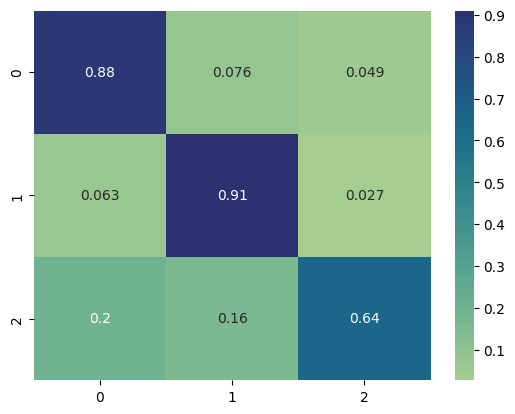

In [89]:
cf = confusion_matrix(y_test, pred, normalize='true')

sns.heatmap(cf, annot=True, cmap='crest')